In [58]:
from dotenv import load_dotenv
import os 
load_dotenv()

True

In [59]:
from langchain.tools import tool
from langchain_community.tools import DuckDuckGoSearchRun

@tool
def searchEngine(query):

    """This is a tool which is used as a  search engine to the network """
    search = DuckDuckGoSearchRun()

    response = search.invoke(query)

    return response


@tool
def addMe(x,y):
    """This tool is used to sum two integer"""
    return x+y


tools = [searchEngine,addMe]


In [60]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-5-mini")
bindllm = llm.bind_tools(tools)

In [61]:
from pydantic import BaseModel
from typing import TypedDict,List ,Annotated 
from langgraph.graph.message import add_messages

class graph_schema(BaseModel):
    mssg: Annotated[list, add_messages]

In [62]:
from langchain_core.messages import ToolMessage ,HumanMessage

def AgentNode(state:graph_schema):

    messages = state.mssg

    response = bindllm.invoke(messages)

    return {"mssg": [response]}

def ToolNode(state:graph_schema):

    lastM = state.mssg[-1]
    tool_with_name = {tool.name:tool for tool in tools}
    result = []

    for i in lastM.tool_calls:

        selected_tools = tool_with_name[i["name"]]
        content = selected_tools.invoke(i["args"])
        result.append(ToolMessage(content=str(content),tool_call_id=i["id"]))

    return {"mssg":result}


def route(state:graph_schema):

    lastM = state.mssg[-1]
    if lastM.tool_calls:
        return "yes"
    else:
        return "no"


In [63]:
from langgraph.graph import StateGraph , START , END

graph = StateGraph(graph_schema)

graph.add_node("AgentNode",AgentNode)
graph.add_node("ToolNode",ToolNode)

graph.add_edge(START,"AgentNode")
graph.add_conditional_edges("AgentNode",route,{"yes":"ToolNode","no":END})
graph.add_edge("ToolNode","AgentNode")

complexGraph = graph.compile()


In [67]:
complexGraph.invoke({"mssg":[HumanMessage(content="What is Marvel's Avenger DoomDays release date in india ")]})

{'mssg': [HumanMessage(content="What is Marvel's Avenger DoomDays release date in india ", additional_kwargs={}, response_metadata={}, id='ddb83dcc-a4ca-4ec3-b926-4e54d2785cc8'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 174, 'total_tokens': 224, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EeUHAPWSbtHXQlnXJbYJJwhfyrTG4', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a18a18-40e1-7372-999b-ecc9db629d70-0', tool_calls=[{'name': 'searchEngine', 'args': {'query': 'Marvel Avengers: Doom Days rel

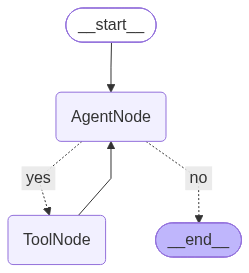

In [65]:
from IPython.display import Image

Image(complexGraph.get_graph().draw_mermaid_png())